#Python DA Assignment 2- Data visualization


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


###2) Handling Missing Values  
####● Check for missing values in the dataset and identify columns with missing data.  

In [2]:
print(df.isnull().sum())
missing_values = df.isnull().sum()
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


####●  Impute missing values using appropriate strategies based on the column type (e.g., using the mean, median, or mode for numerical columns and the mode for categorical columns).

In [3]:
df["distance"] = df["distance"].fillna(df["distance"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())
df["tip"] = df["tip"].fillna(df["tip"].median())
df["tolls"] = df["tolls"].fillna(df["tolls"].median())
df["total"] = df["total"].fillna(df["total"].median())

df["pickup_zone"] = df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"] = df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment             0
pickup_zone         0
dropoff_zone        0
pickup_borough     26
dropoff_borough    45
dtype: int64


#### For columns that are critical and cannot be reasonably imputed, removerows with missing values to maintain data integrity.  

In [4]:
df = df.dropna()
print(df.isnull().sum())
print(df.head())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  cred

##3) Visualizations using Matplotlib/Pandas Plot:  
###★ Line Chart  
####Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

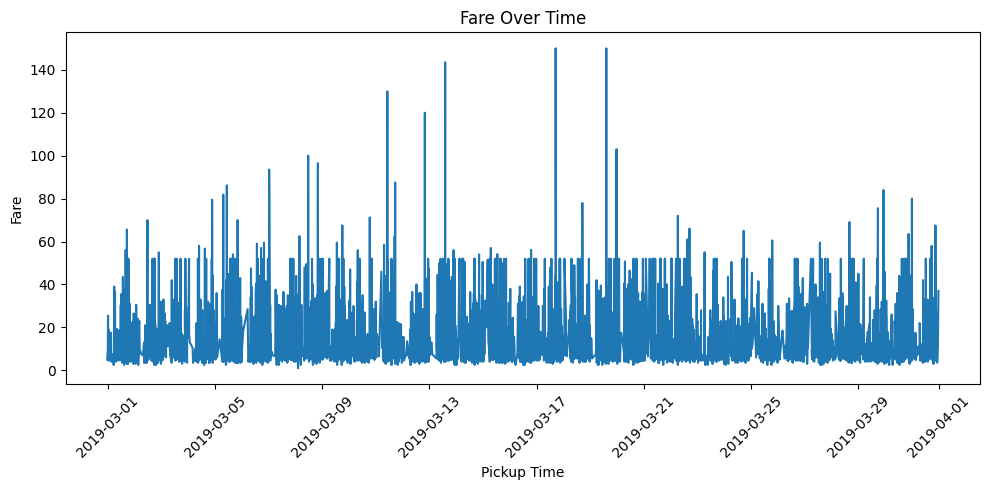

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")
df["pickup"] = pd.to_datetime(df["pickup"])
df = df.sort_values("pickup")
plt.figure(figsize=(10, 5))
plt.plot(df["pickup"], df["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###★ Bar Chart  
####Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.  

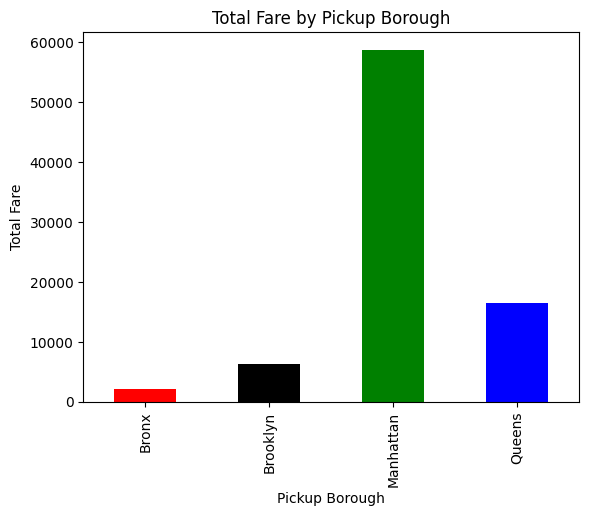

In [16]:
fare = df.groupby("pickup_borough")["fare"].sum()
fare.plot(kind="bar", color=["red", "black", "green", "blue"])
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.show()


###★ Pie Chart  
####Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.  

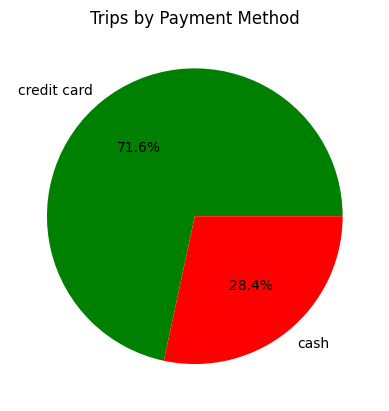

In [18]:
payment_count = df["payment"].value_counts()
payment_count.plot(kind="pie", autopct="%1.1f%%",colors= ["green", "red"])
plt.title("Trips by Payment Method")
plt.ylabel("")
plt.show()

###★ Histogram  
####Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

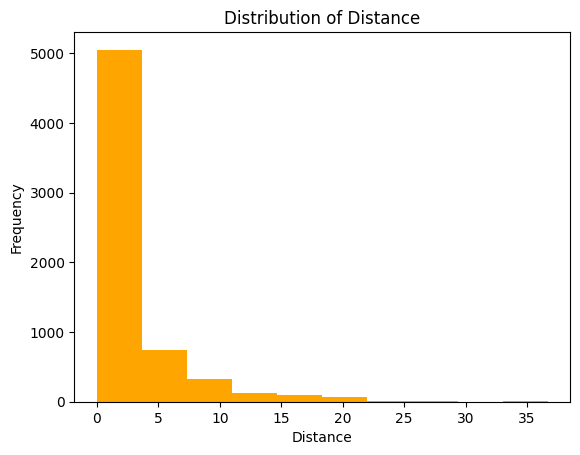

In [29]:
plt.hist(df["distance"], bins=10, color="orange")
plt.title("Distribution of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show()

###★ Box Plot  
####Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis.  

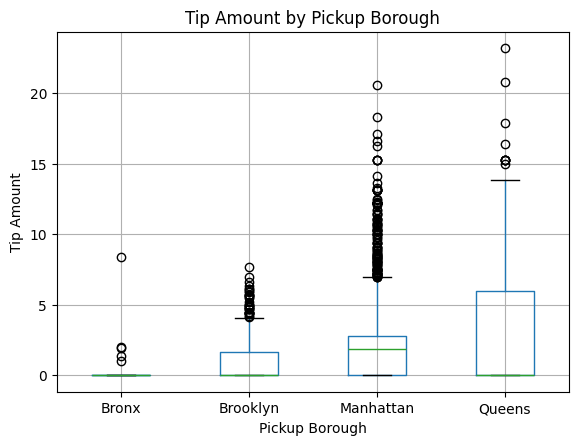

In [33]:
df.boxplot(column="tip", by="pickup_borough")
plt.suptitle("")
plt.title("Tip Amount by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.show()

##Visualizations using Seaborn:  
###★ Count Plot  
####Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips.

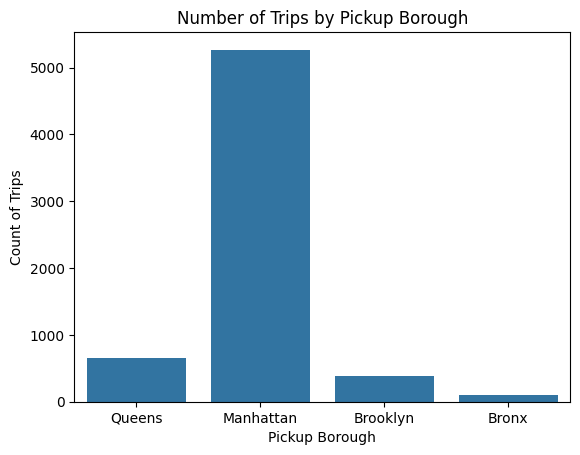

In [35]:
import seaborn as sbn
sbn.countplot(x="pickup_borough", data=df)
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Count of Trips")
plt.show()


###★ Scatter Plot  
####Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.

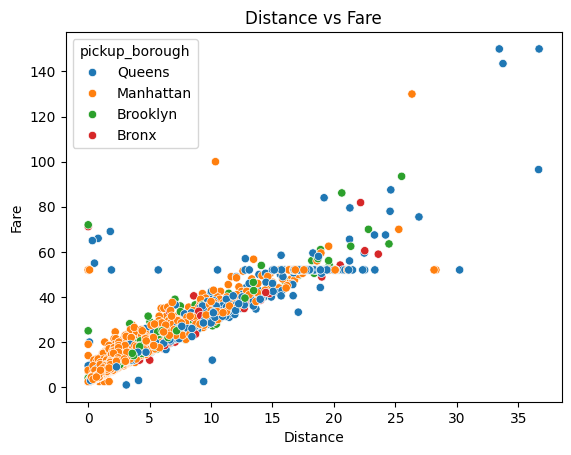

In [43]:

sbn.scatterplot(x="distance", y="fare", hue="pickup_borough", data=df)
plt.title("Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

###★ Heatmap  
####Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the relationships.

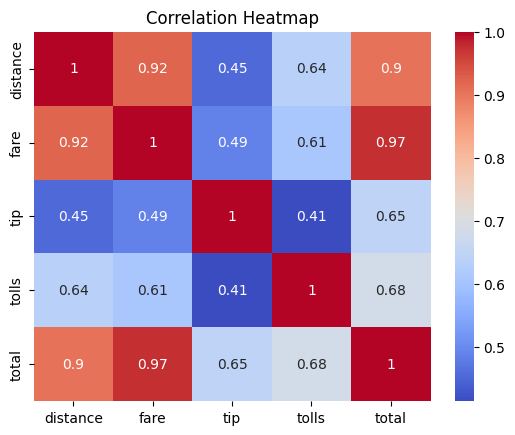

In [44]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
sbn.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

###★ Pair Plot  
####Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to the pickup_zone column. to compare how different zones affect these variables.

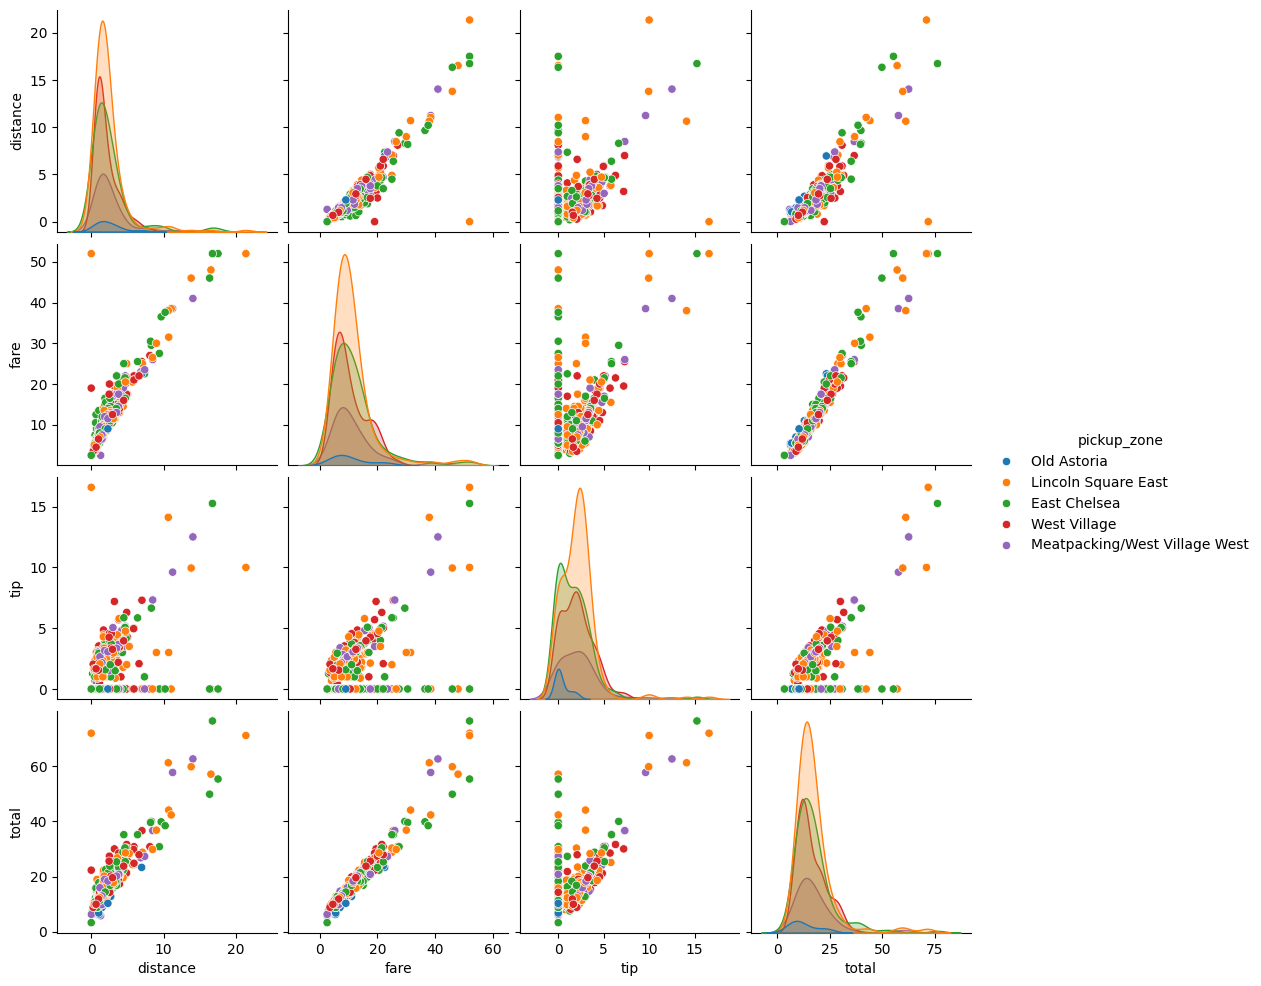

In [45]:
df1 = df[df["pickup_zone"].isin(df["pickup_zone"].dropna().unique()[:5])]
sbn.pairplot(df1, vars=["distance", "fare", "tip", "total"],hue="pickup_zone")
plt.show()

###★ Violin Plot  
####Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

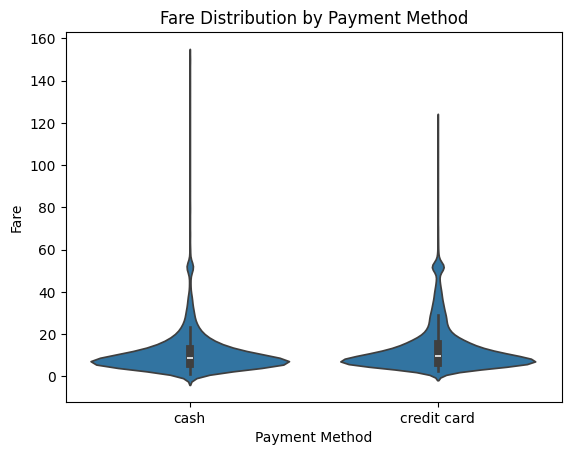

In [46]:
sbn.violinplot(x="payment", y="fare", data=df)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.show()